<a href="https://colab.research.google.com/github/parvezsardar13/Aerofit-business-case/blob/main/Aerofit_Business_Case_study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **About Aerofit**

# Aerofit is a leading brand in the field of fitness equipment. Aerofit provides a product range including machines such as treadmills, exercise bikes, gym equipment, and fitness accessories to cater to the needs of all categories of people.

# **Business Problem**

# The market research team at AeroFit wants to identify the characteristics of the target audience for each type of treadmill offered by the company, to provide a better recommendation of the treadmills to the new customers.

# **Import Required Libraries**

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

***Defining Problem Statement and Analyzing basic metrics***

In [14]:
df=pd.read_csv("aerofit_treadmill.csv")
df.head()

,Product,Age,Gender,Education,MaritalStatus,Usage,Fitness,Income,Miles
0,KP281,18,Male,14,Single,3,4,29562,112
1,KP281,19,Male,15,Single,2,3,31836,75
2,KP281,19,Female,14,Partnered,4,3,30699,66
3,KP281,19,Male,12,Single,3,3,32973,85
4,KP281,20,Male,13,Partnered,4,2,35247,47


In [15]:
df.shape

(180, 9)

### insights:
The dataset contains 180 rows and 9 columns (attributes)

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Product        180 non-null    object
 1   Age            180 non-null    int64 
 2   Gender         180 non-null    object
 3   Education      180 non-null    int64 
 4   MaritalStatus  180 non-null    object
 5   Usage          180 non-null    int64 
 6   Fitness        180 non-null    int64 
 7   Income         180 non-null    int64 
 8   Miles          180 non-null    int64 
dtypes: int64(6), object(3)
memory usage: 12.8+ KB


In [17]:
df.duplicated().sum()

np.int64(0)

### 💡 INSIGHTS
The dataset contains 180 rows and 9 columns with zero
missing or duplicate entries. Each row represents an
individual customer who purchased an Aerofit treadmill,
with attributes covering customer demographics (Age,
Gender, Education, Marital Status, Income) alongside their
fitness usage profile (Product model, weekly Usage
frequency and targeted Miles,etc)


In [18]:
df.nunique()

,0
Product,3
Age,32
Gender,2
Education,8
MaritalStatus,2
Usage,6
Fitness,5
Income,62
Miles,37


In [19]:
# Converting number coded and string value column to category data types
cat_cols = ['Product', 'Gender', 'MaritalStatus', 'Fitness']
for col in cat_cols:
    df[col] = df[col].astype('category')
df.dtypes

,0
Product,category
Age,int64
Gender,category
Education,int64
MaritalStatus,category
Usage,int64
Fitness,category
Income,int64
Miles,int64


In [20]:
df.describe()

,Age,Education,Usage,Income,Miles
count,180.000000,180.000000,180.000000,180.000000,180.000000
mean,28.788889,15.572222,3.455556,53719.577778,103.194444
std,6.943498,1.617055,1.084797,16506.684226,51.863605
min,18.000000,12.000000,2.000000,29562.000000,21.000000
25%,24.000000,14.000000,3.000000,44058.750000,66.000000
50%,26.000000,16.000000,3.000000,50596.500000,94.000000
75%,33.000000,16.000000,4.000000,58668.000000,114.750000
max,50.000000,21.000000,7.000000,104581.000000,360.000000


### 💡 INSIGHTS
Each row represents an
individual customer who purchased an Aerofit treadmill. Customers average 28.8 years of age (median 26) with 15.6 years of education on average. Annual income averages $53,720 (median $50,596.50), but exhibits significant right-skewness and high-value outliers reaching up to $104,581. Customers report an average weekly treadmill usage of 3.5 days and an expected target distance of 103.2 miles, where miles also show prominent extreme upper outliers reaching up to 360 miles

***Non-Graphical Analysis: Value counts and unique attributes***

In [21]:
# Number of unique Values  across all columns
df.nunique()

,0
Product,3
Age,32
Gender,2
Education,8
MaritalStatus,2
Usage,6
Fitness,5
Income,62
Miles,37


In [30]:
print(df_clipped['Product'].value_counts())
print('===============')
print(round(df_clipped['Product'].value_counts(normalize=True)*100,2))

Product
KP281    80
KP481    60
KP781    40
Name: count, dtype: int64
Product
KP281    44.44
KP481    33.33
KP781    22.22
Name: proportion, dtype: float64


### 💡 INSIGHTS
Product: KP281 (entry-level) is the top seller (80 units, 44.44%), followed by KP481 (60 units, 33.33%) and KP781 (40 units, 22.22%).
also the entry-level model (KP281) and mid-level model (KP481) combined account for ~78% of total sales, showing that market demand heavily favors budget-conscious to mid-range products

In [29]:
print(df_clipped['Gender'].value_counts())
print('===============')
print(round(df_clipped['Gender'].value_counts(1)*100,2))

Gender
Male      104
Female     76
Name: count, dtype: int64
Gender
Male      57.78
Female    42.22
Name: proportion, dtype: float64


In [28]:
print(df_clipped['MaritalStatus'].value_counts())
print('===============')
print(round(df_clipped['MaritalStatus'].value_counts(True)*100,2))

MaritalStatus
Partnered    107
Single        73
Name: count, dtype: int64
MaritalStatus
Partnered    59.44
Single       40.56
Name: proportion, dtype: float64


### 💡 INSIGHTS
The primary customers leans toward partnered individuals and male buyers.
Male buyers represent the majority of the customer base overall.
Partnered individuals account for nearly 60% of total treadmill purchases

In [27]:
print(df_clipped['Fitness'].value_counts())
print('========='*5)
print(round(df_clipped['Fitness'].value_counts(normalize=True)*100,2))

Fitness
3.0    97
5.0    31
2.0    28
4.0    24
Name: count, dtype: int64
Fitness
3.0    53.89
5.0    17.22
2.0    15.56
4.0    13.33
Name: proportion, dtype: float64


### 💡 INSIGHTS
Over half of customers rate themselves at Fitness Level 3 (53.89%), followed by Level 5 (17.22%) and Two Third pf customers are belongs to Rate-3 to 5 (~71%)

In [50]:
print(df_clipped['Usage'].value_counts())
print('========='*5)
print(round(df_clipped['Usage'].value_counts(normalize=True)*100,2))

Usage
3.00    69
4.00    52
2.00    33
5.00    17
5.05     9
Name: count, dtype: int64
Usage
3.00    38.33
4.00    28.89
2.00    18.33
5.00     9.44
5.05     5.00
Name: proportion, dtype: float64


💡 INSIGHTS
The most common intended weekly usage is 3 days per week (38.33%), followed by 4 days per week (28.89%) and together 3 and 4 holds over 50%

***Missing Value & Outlier Detection***

In [23]:
df.describe()

,Age,Education,Usage,Income,Miles
count,180.000000,180.000000,180.000000,180.000000,180.000000
mean,28.788889,15.572222,3.455556,53719.577778,103.194444
std,6.943498,1.617055,1.084797,16506.684226,51.863605
min,18.000000,12.000000,2.000000,29562.000000,21.000000
25%,24.000000,14.000000,3.000000,44058.750000,66.000000
50%,26.000000,16.000000,3.000000,50596.500000,94.000000
75%,33.000000,16.000000,4.000000,58668.000000,114.750000
max,50.000000,21.000000,7.000000,104581.000000,360.000000


Insights
Major Outliers Present (Income & Miles) Moderate Outliers (Age) Minimal Outliers (Fitness, Usage, Education) observed from mean median difference

🔬 Find the outliers for every continuous variable in the dataset

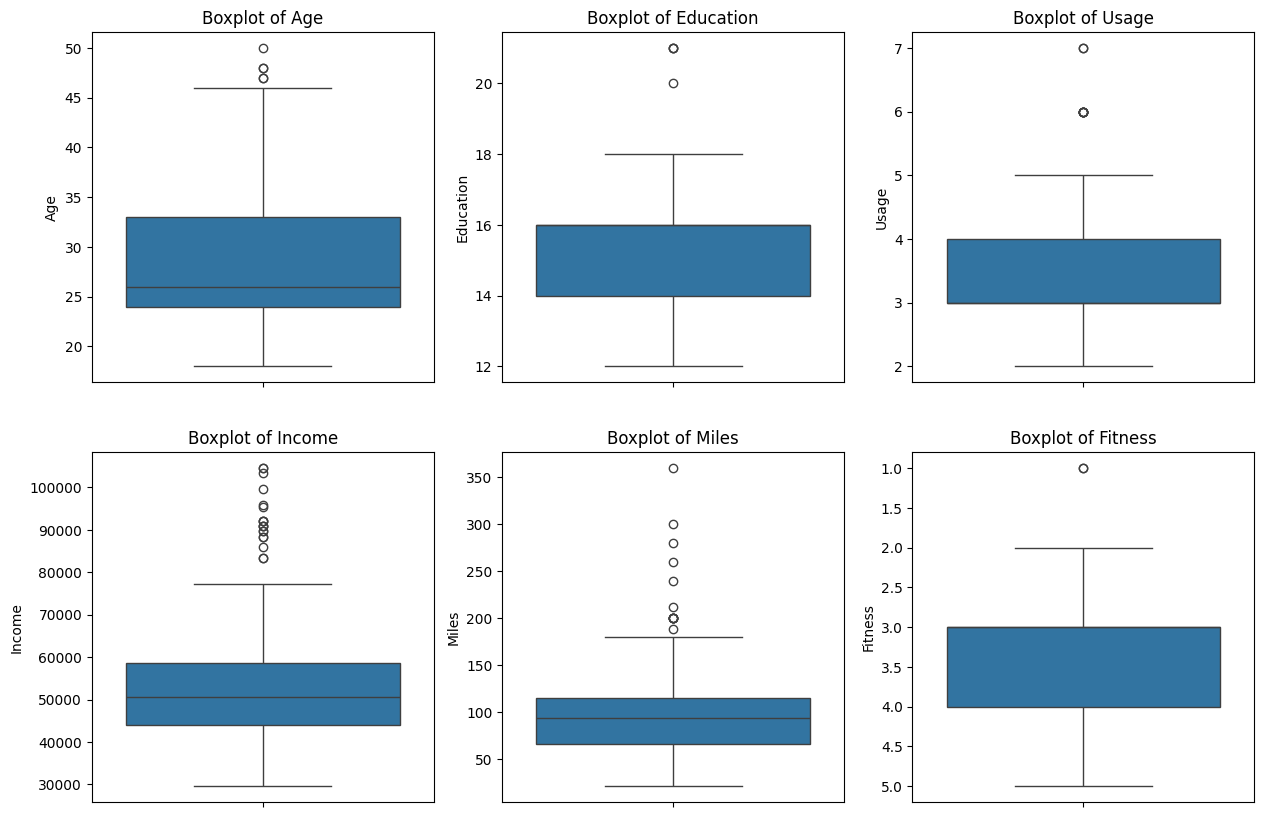

In [24]:
# boxplots for each continuous variable
cont_cols = ['Age', 'Education', 'Usage', 'Income', 'Miles','Fitness']

plt.figure(figsize=(15, 10))

i = 1
for col in cont_cols:
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot of {col}')
    plt.ylabel(col)
    i = i + 1
plt.show()

# 💡 INSIGHTS
## Age:
Core buyers are young adults aged 24–33, with a few older outliers between 45 and 50.

## Education:
Concentration is heavily centered around 14–16 years (mostly associate/bachelor's degrees).

## Usage:
Most customers plan to use treadmills 3–4 times per week, with rare extreme users at 6–7 days.

## Income:
Median earning is nearly 51k USD, with extreme high-earning outliers stretching up to $100k+.
## Miles:
Target distance sits at 60–120 miles/week, though a long right-skew tail reaches up to 360 miles.

## Fitness:
strongly cluster at a moderate 3-4, with minimal representation at 1 or 5.

✂️Clip the data between the 5 percentile and 95 percentile

In [25]:
# List of columns to clip
cont_cols = ['Age', 'Education', 'Usage', 'Income', 'Miles','Fitness']

df_clipped = df.copy()

for col in cont_cols:
    # Calculate 5th and 95th percentiles
    p5 = np.percentile(df[col], 5)
    p95 = np.percentile(df[col], 95)

    # Clip the values outside the 5th and 95th percentile range
    df_clipped[col] = np.clip(df[col], a_min=p5, a_max=p95)
df_clipped[cont_cols].describe()

,Age,Education,Usage,Income,Miles,Fitness
count,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000
mean,28.641389,15.572222,3.396944,53477.070000,101.088889,3.322222
std,6.446373,1.362017,0.952682,15463.662523,43.364286,0.937461
min,20.000000,14.000000,2.000000,34053.150000,47.000000,2.000000
25%,24.000000,14.000000,3.000000,44058.750000,66.000000,3.000000
50%,26.000000,16.000000,3.000000,50596.500000,94.000000,3.000000
75%,33.000000,16.000000,4.000000,58668.000000,114.750000,4.000000
max,43.050000,18.000000,5.050000,90948.250000,200.000000,5.000000


### 💡 INSIGHTS
Extreme Outliers Handled: High-end extreme values have been capped at the 95th percentile—max and 5 percentile-min. Miles reduced from 360 to 200, max Income from  104,581𝑡𝑜 90,948, and max Age from 50 to 43. also reduced outliers at lower ends of Fitness column.

In [31]:
df_clipped.isnull().sum()

,0
Product,0
Age,0
Gender,0
Education,0
MaritalStatus,0
Usage,0
Fitness,0
Income,0
Miles,0


### 💡 INSIGHTS
No missing value Recorded

***Visual Analysis - Univariate & Bivariate***

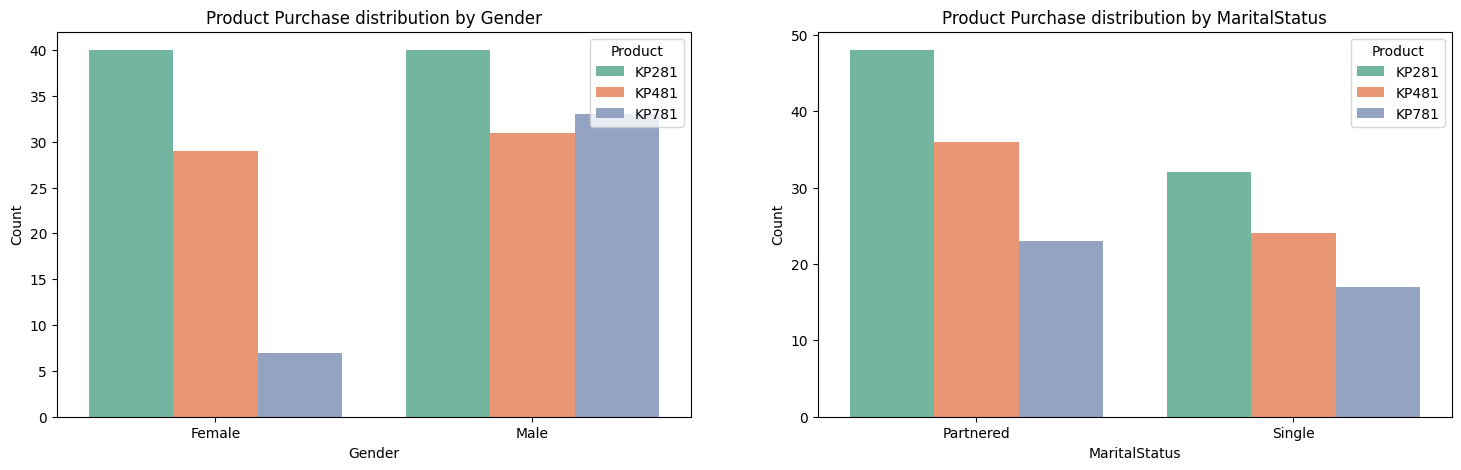

In [32]:
# List of categorical variables
cat_cols = ['Gender', 'MaritalStatus']

# Plot countplots relative to Product purchased
plt.figure(figsize=(18, 5))
i=1
for col in cat_cols:
    plt.subplot(1, 2, i)
    sns.countplot(data=df_clipped, x=col, hue='Product', palette='Set2')
    plt.title(f'Product Purchase distribution by {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    i=i+1
plt.show()

### 💡 INSIGHTS
***Gender wise distribution*** --
for KP281 and KP481 both are almost gender neutral but real gap exist in KP781 here Male outnumbered female in the context of premium product

***MaritalStatus wise distribution*** --
there is huge gap in the context of marital status here single person doesn't match with partnered in all three products but here premium product uses is nearly similar attraction for both single and partnered

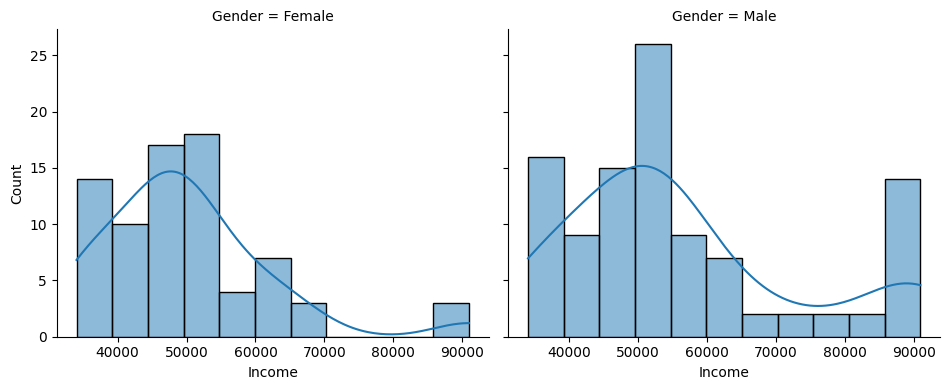

In [33]:
# Gender wise income distribution
sns.displot(data=df_clipped, x='Income',
            col='Gender', kde=True,
            height=4, aspect=1.2)
plt.show()

### 💡 INSIGHTS
***Male Segment***: Bimodal distribution; strong cluster at  35𝑘– 60k, with a distinct secondary high-earner peak at  85𝑘– 90k (KP781 buyers).
***Female Segment***: Right-skewed; heavily concentrated in the  35𝑘– 55k range with very few buyers above $70k.
***Summery***: High-earning male profiles drive the premium market segment

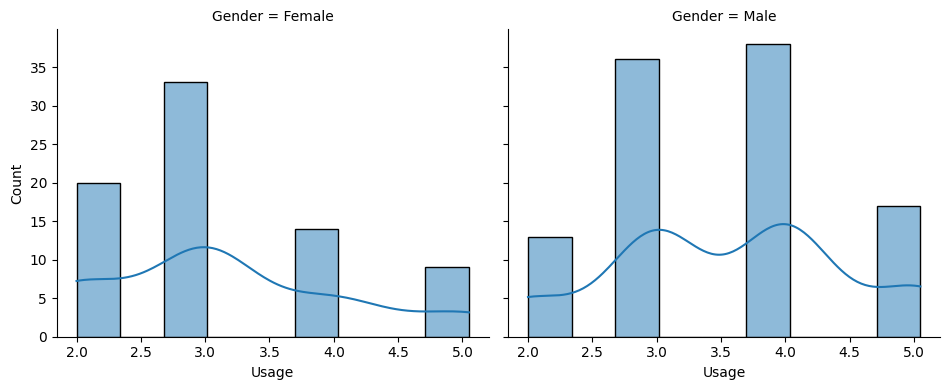

In [34]:
# Gender wise Tredmill usages
sns.displot(data=df_clipped, x='Usage',
            col='Gender', kde=True,
            height=4, aspect=1.2)
plt.show()

### 💡 INSIGHTS
***Male Segment***: Shifted toward higher intensity, peaking at 3 to 5 workouts/week.
***Female Segment***: Centered at moderate intensity, peaking at 2 to 4 workouts/week.
***Key takeaway***: Both genders maintain active exercise routines, but male users show a slightly higher tendency for daily/intense usage.

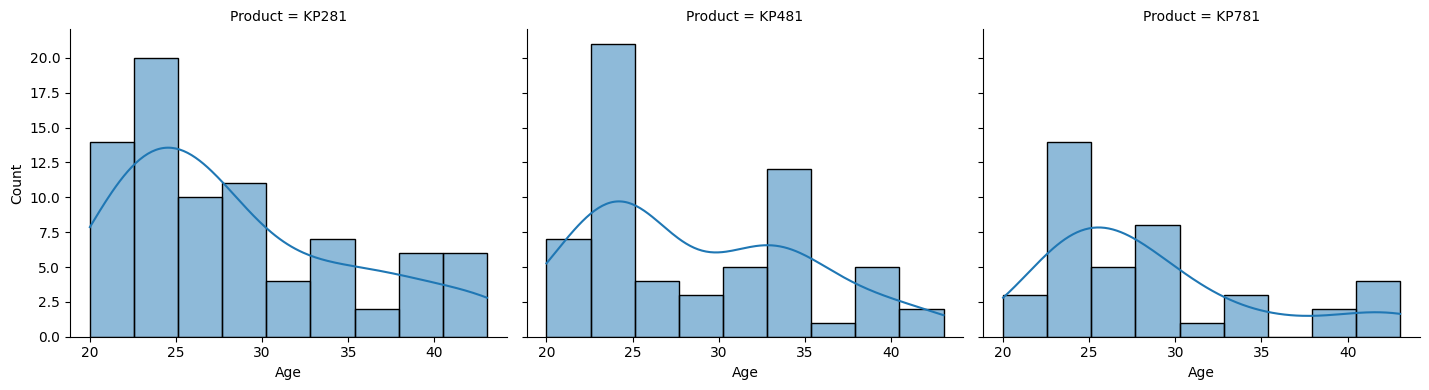

In [35]:
# Age wise product distribution
sns.displot(data=df_clipped, x='Age',
            col='Product', kde=True,
            height=4, aspect=1.2)
plt.show()

### 💡 INSIGHTS
Distrbution of Products --
KP281 -- usually buys age group b/w 20s to early 30s where as KP481 buys b/w 20 to 26 but there is a trends also shown that age group b/w 30 to 35 have also attractcs for this product reason might be budget fiendly with some feature of premium and KP781 specially consumed the age group b/w 23 to 30

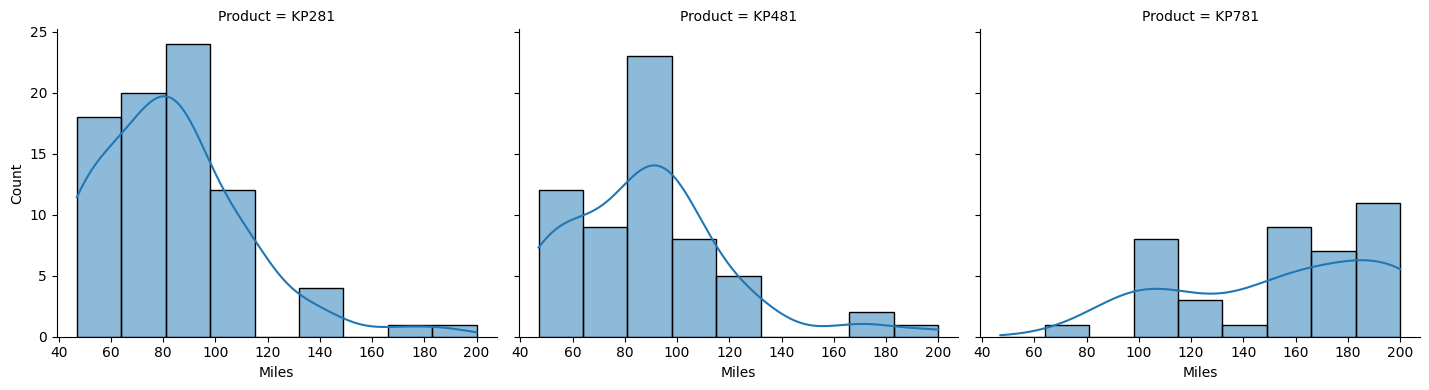

In [36]:
sns.displot(data=df_clipped, x='Miles',
            col='Product', kde=True,
            height=4, aspect=1.2)
plt.show()

### 💡 INSIGHTS
***KP281*** (Entry Level): Target 50–100 miles/week (peak ~80); ideal for light users, casual walkers, and beginners.

***KP481*** (Mid Level): Target 60–120 miles/week (peak ~90–100); serves regular joggers seeking moderate endurance training without premium pricing..

***KP781*** (Premium): Target 100–200+ miles/week (peak ~160–200); heavily preferred by active runners and serious fitness enthusiasts

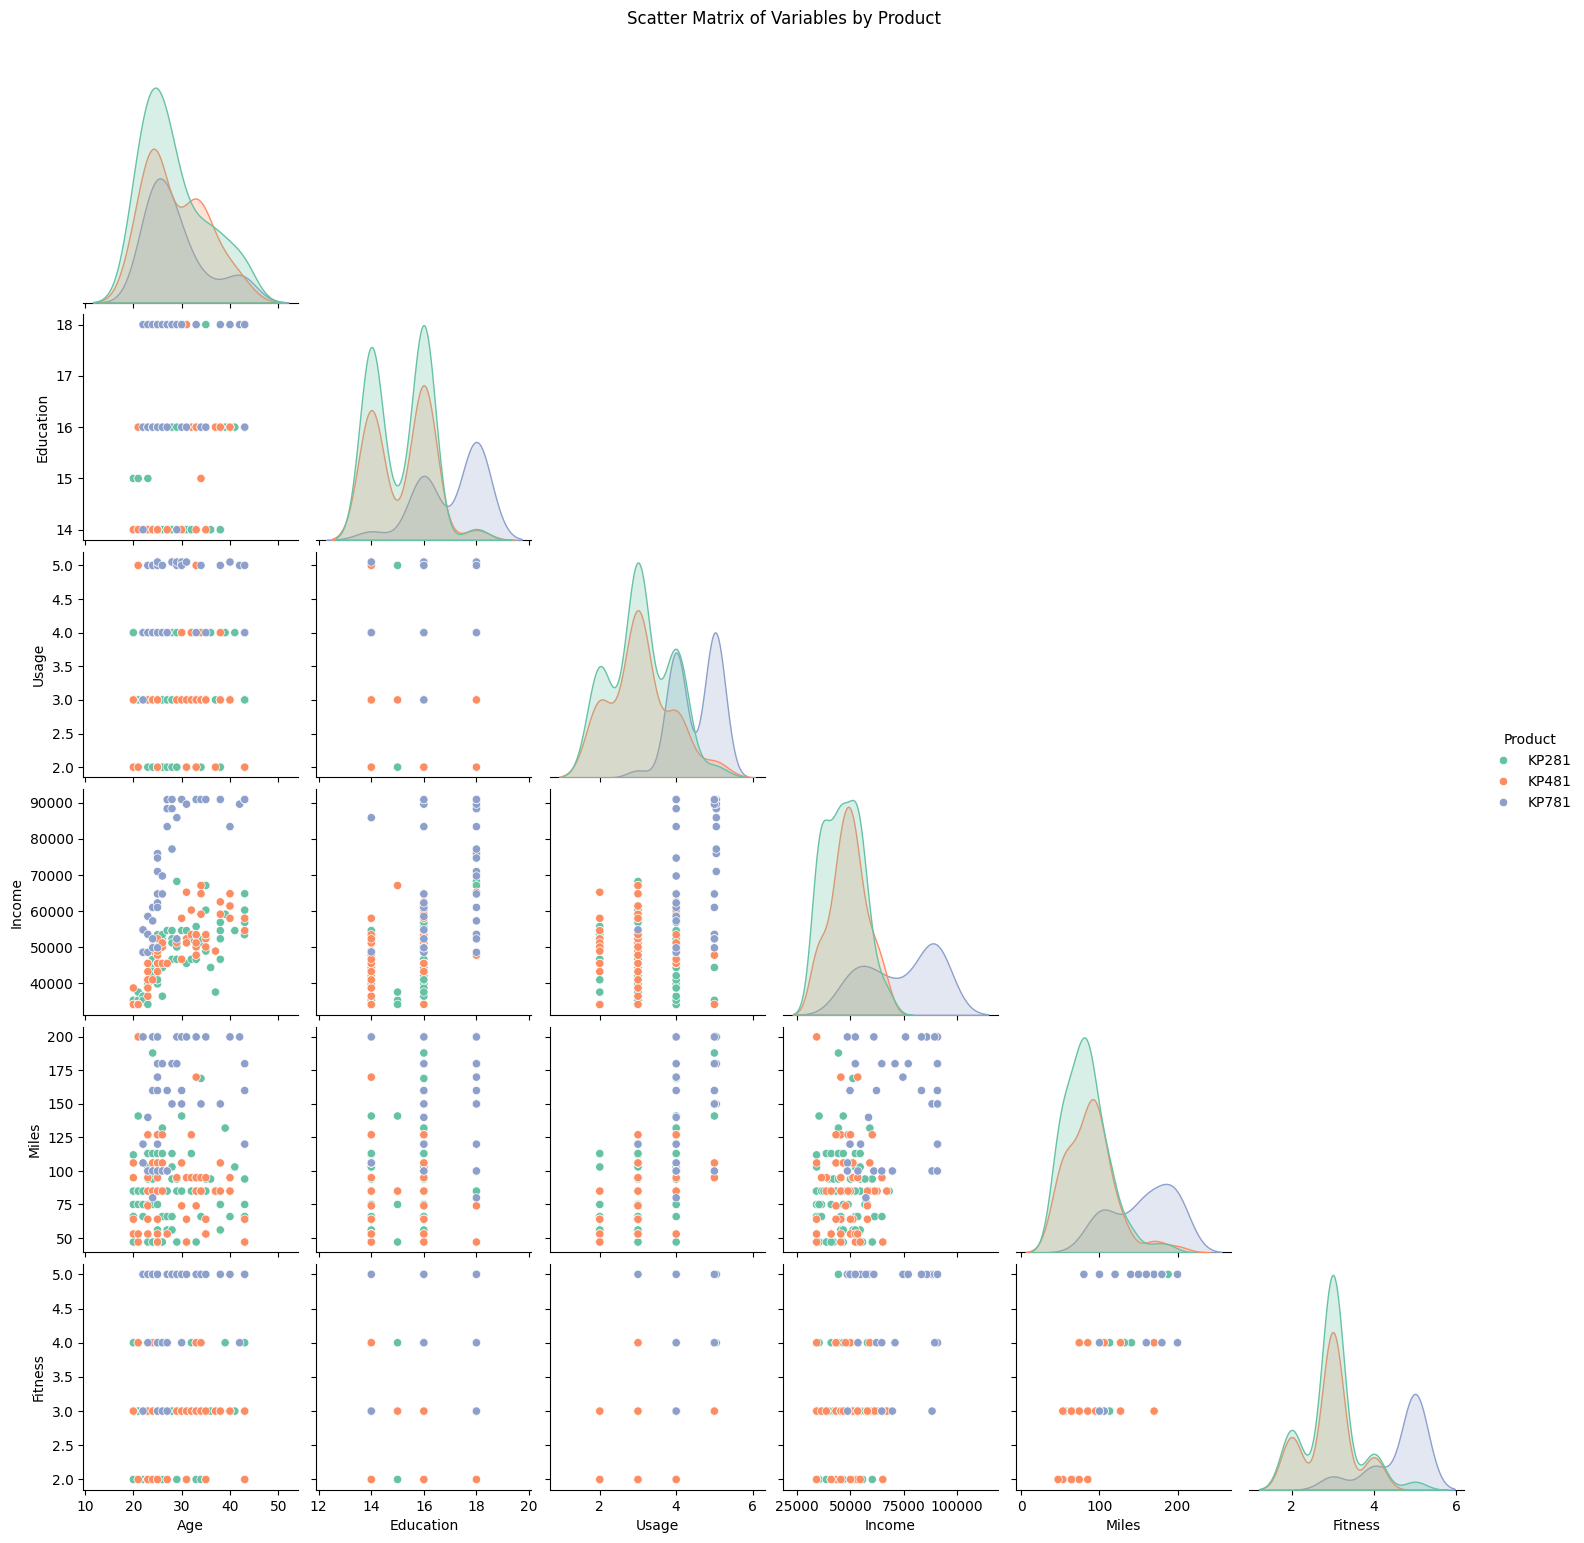

In [37]:
# Product comaprison with feature
# List of columns to pairplot
cols = ['Age', 'Education', 'Usage', 'Income', 'Miles', 'Product','Fitness']

# Pairplot to see all scatter relationships at once
sns.pairplot(df_clipped[cols], hue='Product', corner=True,palette='Set2')
plt.suptitle('Scatter Matrix of Variables by Product',y=1.03)
plt.show()

### 💡 INSIGHTS

***KP281*** -- consumed by people whose income b/w 35k to 55k and weekly uses target 2 to 3 times and education level 14 -15 also wanted to range of miles approx 50 to 80 and most importaintly its for entry level

***KP481*** -- consumed by people whose income b/w 40k to 68k and weekly uses target 3 to 4 times and education level 14 to 16 also wanted to range of miles approx 55 to 120 and most importaintly its for mid level

***KP781*** -- consumed by people whose income b/w 55k to 90k and weekly uses target 4 to 5 times and education level 16 to 18+ also wanted high milege and most importaintly its for premium level

            Age  Education  Usage  Fitness  Income  Miles
Age        1.00       0.30   0.02     0.06    0.51   0.03
Education  0.30       1.00   0.41     0.44    0.63   0.38
Usage      0.02       0.41   1.00     0.66    0.48   0.77
Fitness    0.06       0.44   0.66     1.00    0.55   0.83
Income     0.51       0.63   0.48     0.55    1.00   0.54
Miles      0.03       0.38   0.77     0.83    0.54   1.00


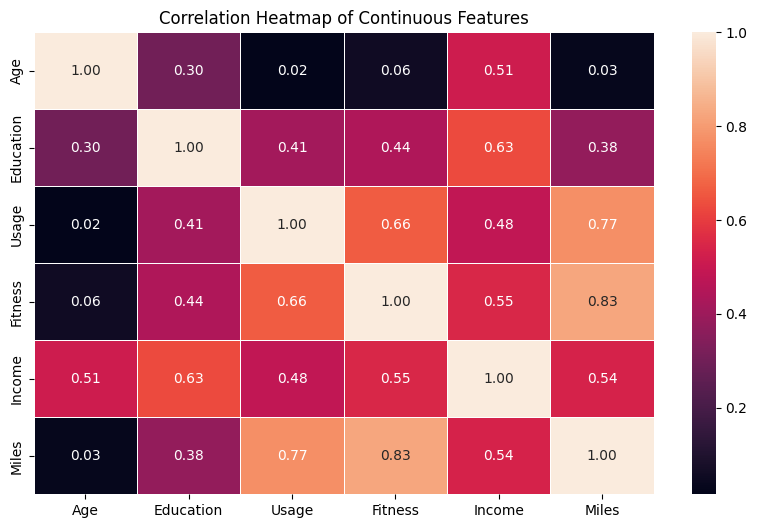

In [38]:
# figuring corelation b/w variables
corr_matrix = df_clipped.corr(numeric_only=True)

# Display numerical correlation matrix
print(corr_matrix.round(2))

# heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Continuous Features')
plt.show()

### 💡 INSIGHTS:

* **Strongest Key Relationships:**
  * **Fitness & Miles (r = 0.83):** Very strong positive correlation. Users who rate their fitness level higher plan to run/walk significantly greater weekly distances.
  * **Usage & Miles (r = 0.77):** Higher weekly treadmill usage directly translates to higher target mileage.
  * **Usage & Fitness (r = 0.66):** Highly fit individuals commit to more frequent workout sessions per week.

* **Demographics & Income Drivers:**
  * **Income & Education (r = 0.63):** Higher levels of education strongly correlate with higher income levels.
  * **Income & Fitness/Miles (r ~ 0.54–0.55):** Higher earners tend to report higher fitness scores and target longer weekly mileage (aligning with purchases of the premium KP781 model).
  * **Age & Income (r = 0.51):** Moderate correlation, indicating income generally increases with age/career progression.

* **Notable Non-Correlations:**
  * **Age vs. Workout Intensity (r ~ 0.02–0.06):** Age has virtually **no correlation** with weekly exercise frequency (`Usage`), self-reported `Fitness`, or weekly target distance (`Miles`). Older customers are purchasing treadmills for similar intensity goals as younger buyers—their purchasing choice is guided more by budget than by age.

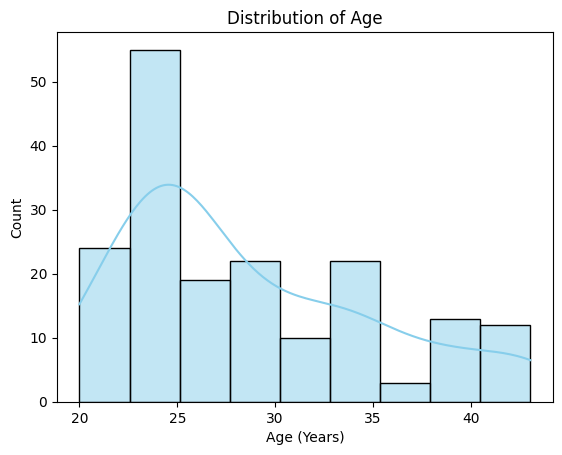

In [39]:
# Age Distribution
sns.histplot(df_clipped['Age'], kde=True, color='skyblue')
plt.title('Distribution of Age')
plt.xlabel('Age (Years)')
plt.ylabel('Count')
plt.show()

### 💡 INSIGHTS:
Moderately right-skewed; heavily concentrated among young adults aged 20–30 years, with participation of older ages also noticible

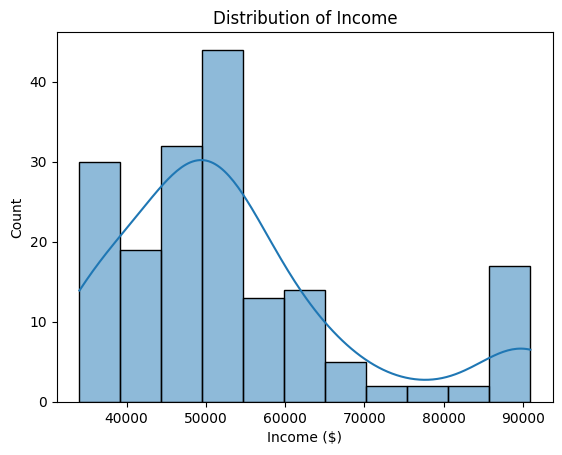

In [40]:
# Income Distribution
sns.histplot(df_clipped['Income'], kde=True)
plt.title('Distribution of Income')
plt.xlabel('Income ($)')
plt.ylabel('Count')
plt.show()

### 💡 INSIGHTS:
Strongly right-skewed; peaks around $40k–$55k, with a long upper tail driven by high-earning buyers might be premium

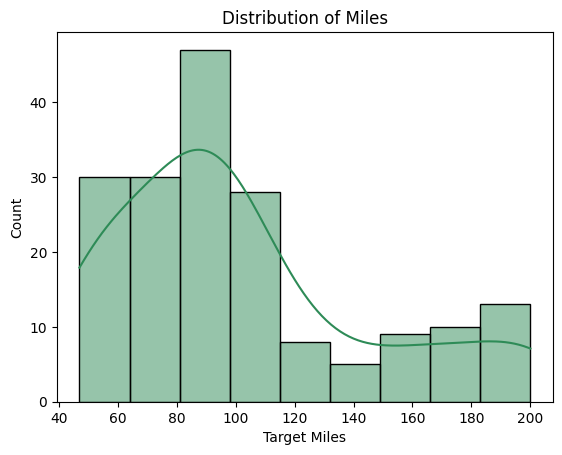

In [41]:
# Miles Distribution
sns.histplot(df_clipped['Miles'], kde=True,color='seagreen')
plt.title('Distribution of Miles')
plt.xlabel('Target Miles')
plt.ylabel('Count')

plt.show()

### 💡 INSIGHTS:
Highly right-skewed; most users target 60–110 miles/week, while a small segment of high-intensity runners aims for 150+ miles

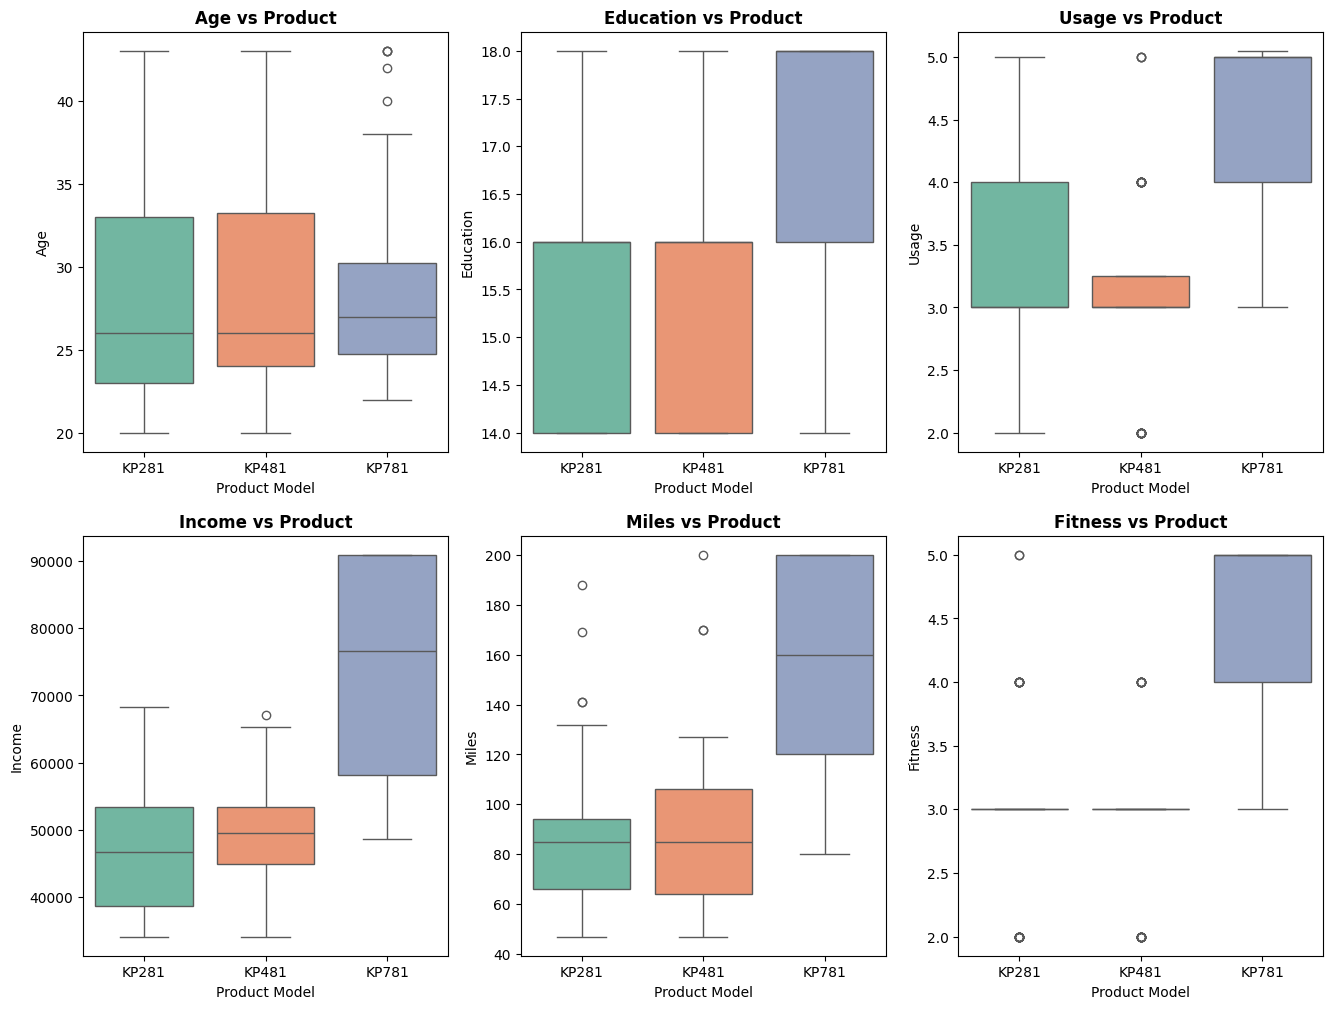

In [42]:
# Boxplots comparing continuous variables across Product models
cont_vars = ['Age', 'Education', 'Usage', 'Income', 'Miles', 'Fitness']

plt.figure(figsize=(16, 12))
i=1
for var in cont_vars:
    plt.subplot(2, 3, i)
    sns.boxplot(data=df_clipped, x='Product', y=var, palette='Set2')
    plt.title(f'{var} vs Product', fontsize=12, fontweight='bold')
    plt.xlabel('Product Model')
    plt.ylabel(var)
    i+=1

plt.show()

***Age***: Customer age distribution remains nearly identical across all three product tiers (median ~26–27 years), showing age alone does not dictate product selection.

***Education & Income***: KP281 and KP481 buyers have similar income bracket (median ~$46k–$49k) and education (~16 yrs) profiles, whereas KP781 buyers earn significantly higher income (median ~$75k) with higher education (median 18 yrs).

***Usage & Miles***: Planned mileage and workout frequency scale directly with product tier—KP781 caters to high-intensity users (median ~160 miles/wk, 4–5 days/wk) compared to KP281/KP481 (median ~85–90 miles/wk, 3-4 days/wk)

***Fitness Rating***: fitness is predominantly Level 3 for KP281 and KP481, while KP781 users overwhelmingly rate themselves at Levels 4 and 5

In [43]:
marginal_prob = pd.crosstab(index=df_clipped['Product'],
                            columns='Probability', normalize=True)

marginal_prob

col_0,Probability
Product,
KP281,0.444444
KP481,0.333333
KP781,0.222222


In [44]:
(marginal_prob * 100).round(2)

col_0,Probability
Product,
KP281,44.44
KP481,33.33
KP781,22.22


### Insights:
𝑃(KP281)  = 44.44% — Highest individual purchase probability; serves as the baseline favorite across customer segments

𝑃(KP481)  = 33.33% — Mid-tier option capturing one-third of the total customer base

𝑃(KP781)  = 22.22% — Niche premium product with lower adoption.




In [45]:
# Marginal probabilities integrated with gender
product_gender_prob = pd.crosstab(
    index=df_clipped['Product'],
    columns=df_clipped['Gender'],
    normalize=True,
    margins=True
)
print(product_gender_prob)

Gender     Female      Male       All
Product                              
KP281    0.222222  0.222222  0.444444
KP481    0.161111  0.172222  0.333333
KP781    0.038889  0.183333  0.222222
All      0.422222  0.577778  1.000000


### Insights:
Gender-Neutral Preferences (KP281 & KP481)equal KP281 Sales: Male ( 22.22% ) and Female ( 22.22% ) buyers contribute equally to total sales for the entry-level model.Similarly KP481 Sales: Male ( 17.22% ) and Female ( 16.11% ) buyers purchase the mid-level treadmill at nearly identical overall proportions.

for KP781 18.33% of all buyers are males who bought the KP781 which is nearly 80% of all kp781 products, compared to only 3.89% who are females

In [46]:
prob_table = pd.crosstab(
        index=df_clipped['Product'],
        columns=df_clipped['Gender'],
        normalize='columns'
    )

prob_pct = (prob_table * 100).round(2)

print(prob_pct)

Gender   Female   Male
Product               
KP281     52.63  38.46
KP481     38.16  29.81
KP781      9.21  31.73


### Insight:
Roughly 1 in 3 male customers purchases the premium KP781 model, compared to only 9.21% of female customers showing that male buyers are over 3 times more likely to purchase the top-tier treadmill

In [47]:
#Marital ststus wise product distribution
prob_table = pd.crosstab(
        index=df_clipped['Product'],
        columns=df_clipped['MaritalStatus'],
        normalize='columns'
    )

prob_pct = (prob_table * 100).round(2)

print(prob_pct)

MaritalStatus  Partnered  Single
Product                         
KP281              44.86   43.84
KP481              33.64   32.88
KP781              21.50   23.29


### Insights:
no major variants noticed almost equal for both parnered and single ..but product preference noticed KP281 is highes then followed by KP481 and KP781

In [48]:
# Probability of Product Purchase based on Fitness
conditional_prob = pd.crosstab(
    index=df_clipped['Product'],
    columns=df_clipped['Fitness'],
    normalize='columns'
) * 100

print(conditional_prob.round(2))

Fitness    2.0    3.0    4.0    5.0
Product                            
KP281    53.57  55.67  37.50   6.45
KP481    46.43  40.21  33.33   0.00
KP781     0.00   4.12  29.17  93.55


### Insights:
Fitness Level 5 have a 93.55% probability of selecting the premium KP781, whereas customers at levels 1–3 avoid it almost entirely
other side Fitness Level 2-3 more prefer KP281 & KP481

In [49]:
# Probability of Product Purchase based on usage
conditional_prob = pd.crosstab(
    index=df_clipped['Product'],
    columns=df_clipped['Usage'],
    normalize='columns'
) * 100

print(conditional_prob.round(2))

Usage     2.00   3.00   4.00   5.00   5.05
Product                                   
KP281    57.58  53.62  42.31  11.76    0.0
KP481    42.42  44.93  23.08  17.65    0.0
KP781     0.00   1.45  34.62  70.59  100.0



High-frequency runners (5 days/week) have an 100 % probability of purchasing the KP781
others 2 to 3 days usages or casual usages can buy KP281 & KP481

***Customer Profiling - Categorization of users***

### 👥 Customer Profiles by Product

* **KP281 (Entry Level):**
  * **Income:** $35k – $55k
  * **Weekly Usage:** 2 to 3 times
  * **Education Level:** 14 to 15 years
  * **Target Distance:** ~50 to 80 miles
  * **Summary:** Budget-friendly model tailored for casual, entry-level users with basic fitness needs.

* **KP481 (Mid Level):**
  * **Income:** $40k – $68k
  * **Weekly Usage:** 3 to 4 times
  * **Education Level:** 14 to 16 years
  * **Target Distance:** ~55 to 120 miles
  * **Summary:** Balanced mid-range model designed for moderate, regular fitness enthusiasts seeking upgraded features.

* **KP781 (Premium Level):**
  * **Income:** $55k – $90k+
  * **Weekly Usage:** 4 to 5+ times
  * **Education Level:** 16 to 18+ years
  * **Target Distance:** High mileage (100–200+ miles)
  * **Summary:** High-performance treadmill targeting highly educated, high-income power users and frequent runners.

***🎯 Business Insights based on Non-Graphical & Visual Analysis***

1. Age: Ranges from 18 to 50 years (mean: 28.8 years, median: 26 years). The distribution is moderately right-skewed indicating concentration of young adults in their 20s
2. Education: Ranges from 12 to 21 years (mean: 15.6 years, median: 16 years), showing that most customers have completed Higher-secondary or graduate-level education
3. Income: Ranges from $29,562 to $104,581 (mean: $53,720, median: $50,596.50). Strong right-skewness and high-value upper outliers ($80k+) reflect a clear divide between standard buyers and high-earning premium buyers.
4.Usage Frequency: Over 67% of buyers plan to use their treadmill 3 to 4 days per week.
5.Rating:Level 3 (average fitness) represents 53.9% of users, while Level 5 represents 17.2%.
6. Income vs. Product Chart: Income is the primary financial differentiator. KP281  and KP481 serve overlapping mid-income brackets, while KP781  exclusively captures high earners.
7.Product preference shows a severe gender skew for the premium model: 82.5% of KP781 buyers are male
8.Age Histplot: Peak buyer age is 23–30 years and a there is also shown buyers from 30s
9.Income Histplot: Concentrated between $40k–$60k
10.Miles Histplot: Most buyers target 60–100 miles/week
11. Product Countplot: KP281 is the overall market leader (44.4%), followed by KP481 (33.3%) and KP781 (22.2%)
12.Income vs. Product Boxplot: Higher income is the single strongest predictor for buying the top-tier KP781 treadmill.
13. Miles vs. Product Boxplot: KP781 users target nearly double the weekly mileage (~160 miles) of KP281/KP481 users (~85–90 miles).
14. Fitness vs. Product Countplot: Fitness Level 5 self-ratings translate directly to KP781 purchases
15. Gender vs. Product Stacked Bar: Female buyers almost exclusively choose entry or mid-tier models (KP281/KP481 account for 90.8% of female purchases)
16.Correlation Heatmap: Income, Miles, and Usage display strong positive correlations ($r > 0.50$), indicating that heavy users possess both high fitness ambitions and high spending capacity



***Recommendations***

***KP281 (Entry-Level Model)***
***Who to Target:*** Casual walkers, beginners, and budget-conscious buyers seeking an accessible everyday treadmill.
***What to Do:***
Highlight value for money, ease of use, compact design, and features suited for walking or light jogging


***KP481 (Mid-Level Model)***
***Who to Target:*** Regular joggers and fitness enthusiasts who want enhanced durability and features without paying top-tier prices.
***What to Do:***
This as the "sweet spot" or best-value upgrade for consistent runners who need a sturdy machine for 3–4 workouts a week.
***# use sales team aggresive here***

***KP781 (Premium Model)***
***Who to Target:*** High-earning, highly active runners and endurance athletes who workout 5+ days a week or run long weekly distances.
***What to Do:***
1.Emphasize high performance, premium build quality, advanced workout tracking, and heavy-duty motor capability.
2. Direct premium marketing campaigns towards  male high-earners
3. Female engagement strategy should more focus here as female buyers here very limited so here is a high scope

1. Target marketing by income & fitness, not just demographics
Since income and fitness level (not age or marital status) are the strongest differentiators of product tier, Aerofit should segment campaigns primarily on income bracket + self-reported fitness/activity level rather than broad demographic targeting

2. With ~80% of KP781 buyers male, there's a clear untapped opportunity in high-income, fitness-driven female customers. promote family package discounts

3. KP481 as the upsell target some customers are choosing it as a budget-conscious alternative to KP781 rather than a natural mid-tier pick.

4.Since purchase probability by marital status showed no major variation across tiers, Aerofit should deprioritize marital status in targeting models/campaigns

5. sell strategy for KP281 buyers and also Retantion of loyal customers --- Aerofit can build a 12–18 month lifecycle upsell campaign nudging KP281 owners toward KP481 as their reported fitness level rises — using loyalty/upgrade offers.

6. some limitation also observed
Small sample size With only 180 observations across 3 products are too small to draw statistically robust conclusions

The dataset is a single snapshot at purchase — there's no repeat-purchase, churn, or actual treadmill-usage-over-time data to validate whether the KP281→KP481 upsell trajectory (Recommendation 5) actually holds.
7. As young adults are very active towards fitnes so aerofit must focus campaign towards unversity students or young working professional